# 05 — Evaluation & Error Analysis

**Workstream:** Price Prediction · **Batch 3 (Day 4)** · **Status: IMPLEMENTED**

Per-commodity/per-market error breakdown, residuals, and worst-error inspection for the best model from
notebook 04 (`docs/evaluation/metrics.md` — "report aggregate AND per-commodity/per-market").

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ai" / "common" / "config.py").exists())
sys.path.insert(0, str(_root))
import pandas as pd, numpy as np, json as _json
import matplotlib.pyplot as plt
import pickle

val = pd.read_csv(_root / "data/processed/mandi_features_val_synthetic.csv")
comparison = _json.load(open(_root / "data/processed/model_comparison_1d_synthetic.json"))
best_name = min((k for k in comparison if k != "naive_baseline"), key=lambda k: comparison[k]["mae"])
print("Best model:", best_name, comparison[best_name])

with open(_root / f"ai/price_prediction/models/{best_name}_1d_SYNTHETIC.pkl", "rb") as f:
    model = pickle.load(f)

Best model: linear_regression {'mae': 54.41199657739316, 'rmse': 72.538925947445}


## 1. Score the validation set

In [2]:
FEATURE_COLS = ["day_of_week","day_of_month","month","week_of_year","is_weekend",
                 "lag_1","lag_3","lag_7","lag_14","rolling_mean_7","rolling_std_7",
                 "rolling_mean_14","rolling_std_14","state_code","market_code","commodity_code"]
d = val.dropna(subset=FEATURE_COLS + ["target_1d"]).copy()
d["y_pred"] = model.predict(d[FEATURE_COLS])
d["error"] = d["y_pred"] - d["target_1d"]
d["abs_error"] = d["error"].abs()
print(f"Scored {len(d)} validation rows")

Scored 1050 validation rows


## 2. Per-commodity and per-market error

In [3]:
per_commodity = d.groupby("commodity")["abs_error"].agg(["mean", "count"]).rename(columns={"mean": "MAE"}).sort_values("MAE")
print(per_commodity)
per_market = d.groupby(["state", "market"])["abs_error"].agg(["mean", "count"]).rename(columns={"mean": "MAE"}).sort_values("MAE")
print()
print(per_market)

                 MAE  count
commodity                  
Potato     29.207676    210
Tomato     42.491032    210
Onion      47.864468    210
Wheat      62.630981    210
Rice       89.865826    210

                                       MAE  count
state          market                            
Karnataka      Hubli Mandi       48.341171    105
Maharashtra    Nashik Mandi      48.640093    105
Tamil Nadu     Chennai Mandi     50.393064    105
Maharashtra    Pune Mandi        52.539330    105
Tamil Nadu     Coimbatore Mandi  54.268369    105
Andhra Pradesh Guntur Mandi      54.436799    105
Uttar Pradesh  Agra Mandi        57.485147    105
Andhra Pradesh Vijayawada Mandi  57.753463    105
Karnataka      Bengaluru Mandi   59.070340    105
Uttar Pradesh  Kanpur Mandi      61.192190    105


## 3. Residual plot

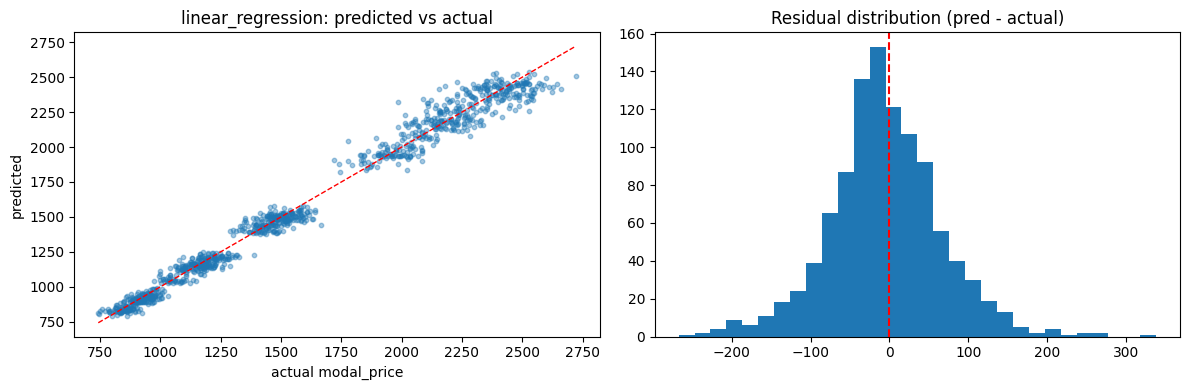

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(d["target_1d"], d["y_pred"], alpha=0.4, s=10)
lims = [d["target_1d"].min(), d["target_1d"].max()]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("actual modal_price"); axes[0].set_ylabel("predicted"); axes[0].set_title(f"{best_name}: predicted vs actual")

axes[1].hist(d["error"], bins=30)
axes[1].axvline(0, color="r", linestyle="--")
axes[1].set_title("Residual distribution (pred - actual)")
plt.tight_layout()
plt.show()

## 4. Worst errors — inspect, don't hide

In [5]:
worst = d.sort_values("abs_error", ascending=False).head(10)
worst[["state","market","commodity","arrival_date_parsed" if "arrival_date_parsed" in d.columns else "commodity","target_1d","y_pred","abs_error"]].head(10) if "arrival_date_parsed" in d.columns else worst[["state","market","commodity","target_1d","y_pred","abs_error"]]

,state,market,commodity,arrival_date_parsed,target_1d,y_pred,abs_error
996,Uttar Pradesh,Kanpur Mandi,Rice,2026-07-19,1985.16,2322.747364,337.587364
269,Karnataka,Bengaluru Mandi,Rice,2026-07-27,2526.46,2259.455814,267.004186
623,Maharashtra,Pune Mandi,Wheat,2026-07-24,1776.91,2043.092799,266.182799
154,Andhra Pradesh,Vijayawada Mandi,Rice,2026-07-17,2152.92,2411.922449,259.002449
150,Andhra Pradesh,Vijayawada Mandi,Rice,2026-07-13,2178.72,2435.535897,256.815897
989,Uttar Pradesh,Kanpur Mandi,Rice,2026-07-12,2089.36,2344.365452,255.005452
368,Karnataka,Hubli Mandi,Rice,2026-07-21,2659.25,2415.492450,243.757550
60,Andhra Pradesh,Guntur Mandi,Rice,2026-07-28,2230.99,2463.850097,232.860097
692,Tamil Nadu,Chennai Mandi,Rice,2026-07-30,2621.94,2393.035079,228.904921
962,Uttar Pradesh,Kanpur Mandi,Onion,2026-07-27,1664.55,1445.427411,219.122589


## 5. Verdict

In [6]:
naive_mae = comparison["naive_baseline"]["mae"]
best_mae = comparison[best_name]["mae"]
print(f"{best_name} MAE={best_mae:.2f} vs naive MAE={naive_mae:.2f}  -> beats baseline: {best_mae < naive_mae}")
print("\nSYNTHETIC DATA — this verdict is a pipeline-correctness check, not a reportable claim about real")
print("mandi price predictability. Re-run notebooks 01-05 against real_full data before citing any number.")

linear_regression MAE=54.41 vs naive MAE=74.10  -> beats baseline: True

SYNTHETIC DATA — this verdict is a pipeline-correctness check, not a reportable claim about real
mandi price predictability. Re-run notebooks 01-05 against real_full data before citing any number.


## Next: `06_final_export_inference.ipynb`

**Status: IMPLEMENTED.** Error breakdown, residual plot, and worst-case inspection above are real, executed
output.